# EveryMind 988 survey: cleaning + analysis pipeline

This notebook walks through every cleaning step on the survey export, shows what each step changed, and then
stress-tests the pipeline on modified copies of the data to show it handles future exports.

**How to run:** put the export in `data/`, set `DATA_PATH` below, then *Run All*. Core steps live in `everymind_clean.py`; the release gate and output
contract live in `release.py`. The app should call `release.run_pipeline` so it gets the same safeguards.

**Design rules**

1. **Flag, never silently delete.** Only exact duplicate rows and fully blank rows are removed.
2. **Never impute an answer.** Every missing value carries a status saying *why* it is missing.
3. **Every mapping is explainable:** exact, alias, or human-approved. Contains/fuzzy matches are only suggestions in the review queue.
4. **Unknown values go to a human**, never guessed into a category.
5. **Privacy first.** No comment strings or raw mapping-review values enter shareable outputs.
   Raw comments and detailed reviews live only in `private/`, which must not be shared.
6. **Config, not code.** New wording or labels mean editing `schema.json` / `mapping_registry.json`.

In [1]:
import warnings
warnings.simplefilter("default")
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

import everymind_clean as ec
import privacy_adapter


pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

DATA_PATH = Path("data/BuildFest_EveryMind_Survey_Data_FULL.xlsx")
SCHEMA, REGISTRY = "schema.json", "mapping_registry.json"
OUT_DIR, PRIVATE_DIR = Path("outputs"), Path("private")

# Connect the team privacy tool here when it is ready, e.g.:
# from privacy_tool import redact
# privacy_adapter.connect(redact)
print("Privacy tool:", privacy_adapter.tool_name())

Privacy tool: not connected


In [2]:
# Release safeguards and the output contract live in release.py (shared with tests and the app).
from release import (GROUPS, QUALITY_FLAGS, clean_frame, derive_release_fields, flag_quality, infer_availability,
                     load_clean, match_input, parse_input, public_data, release_checks, require_ready, run_manifest,
                     safe_audit, standardize_input, write_release)


## 0. Load the configuration

In [3]:
cfg = ec.load_config(SCHEMA, REGISTRY)
audit = ec.Audit()
spec = pd.DataFrame(cfg["columns"]).T[["type", "required"]].fillna(False)
print(f"{len(spec)} schema fields ({int(spec.required.sum())} required), "
      f"{cfg['_registry_count']} human-approved mappings loaded from {REGISTRY}")
spec

21 schema fields (8 required), 3 human-approved mappings loaded from mapping_registry.json


,type,required
response_id,id,True
student_id,drop,False
start_time,datetime,False
completion_time,datetime,False
form_language,category,False
role,multiselect,True
training_date,date,False
county,category,False
identify_after,likert5,True
describe_after,likert5,True


## 1. Ingest
XLSX and CSV share one reader. `N/A` is retained as text. The release manifest combines the input hash with transformation and environment versions to identify each run.

In [4]:
raw = ec.ingest(DATA_PATH, cfg, audit)
# No raw headers or example values: new columns can contain identifiers.
profile = pd.DataFrame([{"source column": i + 1, "non_blank": int(raw[c].notna().sum()),
                         "unique": int(raw[c].nunique())} for i, c in enumerate(raw.columns)])
print(f"Input: {raw.shape[0]} rows x {raw.shape[1]} columns")
profile

Input: 1299 rows x 20 columns


,source column,non_blank,unique
0,1,1299,1299
1,2,1299,1293
2,3,1299,1299
3,4,1299,2
4,5,1299,17
5,6,1296,46
6,7,1299,15
7,8,1299,5
8,9,1299,5
9,10,1299,5


## 2. Match columns to the schema
Exact match on normalized headers first, then fuzzy matching with guard words (`must_contain` /
`must_not_contain`) so, for example, a *before* item can never be matched to an *after* item. A missing required
column stops the run with an error naming the closest header; a missing optional column just disables the analyses
that need it.

In [5]:
df = match_input(raw, cfg, audit)
pd.DataFrame([(k, raw.columns.get_loc(v[0]) + 1, v[1]) for k, v in df.attrs["column_methods"].items()],
             columns=["schema field", "source column number", "method"])

,schema field,source column number,method
0,response_id,1,exact
1,start_time,2,exact
2,completion_time,3,exact
3,form_language,4,exact
4,role,5,exact
5,training_date,6,exact
6,county,7,exact
7,identify_after,8,exact
8,describe_after,9,exact
9,when_after,10,exact


## 3–4. Drop identifier columns, normalize text

In [6]:
df = ec.drop_structured_pii(df, cfg, audit)
before_norm = df.copy()
df = ec.normalize_values(df, cfg, audit)
print(audit.steps[-1]["summary"])
cats = ["form_language", "role", "county", "presenter_engaged", "presenter_knowledge", "well_organized"]
pd.DataFrame({"distinct labels before": before_norm[cats].nunique(), "after normalization": df[cats].nunique()})

Unicode/whitespace/quote normalization changed 3581 cells in 7 columns (includes trailing non-breaking spaces and invisible direction marks).


,distinct labels before,after normalization
form_language,2,2
role,17,17
county,15,10
presenter_engaged,7,7
presenter_knowledge,7,7
well_organized,7,7


## 5. Deduplicate

In [7]:
df = ec.deduplicate(df, cfg, audit)
print(audit.steps[-1]["summary"])

Removed 0 exact duplicate row(s) (1299 → 1299). Flagged 0 rows sharing an ID and 0 rows with identical answers and timestamps under different IDs for operator review (kept).


## 6. Parse dates, durations and numeric scales
Survey duration comes from start/completion timestamps. The lag between the typed training date and the survey
submission catches date-entry errors; those rows are flagged, not corrected.

In [8]:
df = parse_input(df, cfg, audit)
display(pd.DataFrame(audit.steps[-1]["details"]).T)
df["duration_seconds"].describe(percentiles=[.05, .25, .5, .75, .95]).round(1).to_frame("survey duration (s)").T

,blank,unparseable,out_of_range_or_unparseable,negative_set_missing,median,submitted_before_training,submitted_more_than_60_days_after,median_lag_days
start_time,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
completion_time,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
training_date,3.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
recommend,33.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN
call_intent,1006.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN
duration_seconds,NaN,NaN,NaN,0.0,47.0,NaN,NaN,NaN
training_date_vs_submission,NaN,NaN,NaN,NaN,NaN,1.0,10.0,7.0


,count,mean,std,min,5%,25%,50%,75%,95%,max
survey duration (s),1299.0,120.9,426.0,10.0,24.0,33.0,47.0,81.0,319.0,8295.0


## 7. Standardize labels
Labels are applied only on an exact, alias, or human-approved (`mapping_registry.json`) match. Anything else goes to
the review queue, with a suggestion when it contains exactly one known name (e.g. *Montgomery County with NAMI MC*)
or is a close fuzzy match. Suggestions are never applied automatically; approve them in the registry and rerun.

**Fuzzy matching is switched off for Likert labels** because *strongly agree* and *strongly disagree* are about
90% similar as strings. Anything unmatched goes to the review queue below.

In [9]:
pre = df.copy()
df = standardize_input(df, cfg, audit)
display(df["county"].value_counts(dropna=False).rename("mapped county count").to_frame())

,mapped county count
county,
Anne Arundel,937
Prince George's,309
Montgomery,34
Queen Anne's,12
Fairfax,6
Harris,1


In [10]:
role_cols = [c for c in df.columns if c.startswith("role_") and not c.startswith("role__")]
print(f"Role field: {pre['role'].nunique()} raw combinations -> one flag per role:")
display(df[role_cols].sum().rename("respondents").to_frame().T)
print(f"{int((df['role__n'] > 1).sum())} respondents selected more than one role and count once in each.")
lab = "presenter_engaged"
display(df[lab].value_counts(dropna=False).rename("mapped rating count").to_frame())
display(Markdown("**Methods used per column:**"))
pd.DataFrame(audit.steps[-1]["mapping_methods"]).fillna(0).astype(int).T

Role field: 17 raw combinations -> one flag per role:


,role_student,role_staff,role_caregiver,role_other
respondents,1080,68,71,95


14 respondents selected more than one role and count once in each.


,mapped rating count
presenter_engaged,
5.0,579
4.0,433
NaN,151
3.0,98
1.0,24
2.0,14


**Methods used per column:**

,alias,exact,approved
form_language,1299,0,0
role,0,1314,0
county,0,1298,1
identify_after,0,1299,0
describe_after,0,1299,0
when_after,0,1299,0
identify_before,0,1299,0
describe_before,0,1299,0
when_before,0,1299,0
presenter_engaged,98,1027,23


In [11]:
rq = audit.review_table()
print(f"Values awaiting private human review: {len(rq)}")
rq.groupby(["vocab", "column"])["count"].sum().rename("affected cells").to_frame()

Values awaiting private human review: 0


,,affected cells
vocab,column,


## 8. Infer question availability
Date × county is a proxy for a session, not a verified session ID. Low response rates yield
**suspected_not_asked**, not proof that a question was absent. Unknown session keys remain uncertain.
The output preserves observed blankness, session answer rates, and an explicitly inferred version signature.
Columns absent from the export have status **not_in_export**; no answers are imputed.

In [12]:
df = infer_availability(df, cfg, audit)
print("Question availability is inferred, not confirmed form metadata.")
display(pd.DataFrame({c: df[c].value_counts() for c in df if c.endswith("__status")}).fillna(0).astype(int))

Question availability is inferred, not confirmed form metadata.

,start_time__status,completion_time__status,training_date__status,recommend__status,call_intent__status,form_language__status,role__status,county__status,identify_after__status,describe_after__status,when_after__status,identify_before__status,describe_before__status,when_before__status,presenter_engaged__status,presenter_knowledge__status,well_organized__status
skipped,0,0,3,32,11,0,0,0,0,0,0,0,0,0,31,34,38
suspected_not_asked,0,0,0,0,970,0,0,0,0,0,0,0,0,0,119,119,119
unclear_asked,0,0,0,1,25,0,0,0,0,0,0,0,0,0,1,1,1
valid,1299,1299,1296,1266,293,1299,1299,1299,1299,1299,1299,1299,1299,1299,1148,1145,1141


## 9. Free text
Each comment is classified (blank / unclear / none stated / substantive), its language is detected, and it is
checked for distress language. The team privacy tool is called through `privacy_adapter.py`; until it is connected,
the in-memory `__redacted` columns stay empty and **no comment text may be sent to an AI model**.

Distress hits go only to `private/distress_review_*.csv` for staff. This is not crisis monitoring: responses are
anonymous, so EveryMind should decide what a flag triggers.

In [13]:
df, private = ec.process_text(df, cfg, audit)
det = audit.steps[-1]["details"]
display(pd.DataFrame({c: v["categories"] for c, v in det.items()}).fillna(0).astype(int))
display(pd.DataFrame({c: v["languages"] for c, v in det.items()}).fillna(0).astype(int))
print("Distress flags (count only):", {c: v["distress_flags"] for c, v in det.items()})
print("Privacy status:", df["most_valuable__privacy"].value_counts().to_dict())

,most_valuable,improve
substantive,1062,569
blank,236,648
unclear,1,19
none_stated,0,63


,most_valuable,improve
en,993,593
es,70,58


Distress flags (count only): {'most_valuable': 0, 'improve': 0}
Privacy status: {'pending': 1063, 'blank': 236}


In [14]:
spanish_comment = df["most_valuable__lang"].eq("es") | df["improve__lang"].eq("es")
pd.crosstab(df["form_language"].rename("form language chosen"),
            spanish_comment.rename("wrote a comment in Spanish"), margins=True)

wrote a comment in Spanish,False,True,All
form language chosen,,,
en,1224,56,1280
es,3,16,19
All,1227,72,1299


Comment-language labels are heuristic annotations. Compare form language and comment language as different measures; privately validate an English/Spanish sample before interpreting language differences.

## 10. Quality flags (kept, not deleted)
- **fast:** below the configured duration threshold; unavailable timing means not assessed.
- **straightline:** identical answers on the configured full set of rating items; incomplete sets are not assessed.
- **discordant response pattern** (`flag_scale_misread`, retained for compatibility): the configured low post-rating / high presenter-rating pattern. This does not establish that a respondent misunderstood the scale.

Flags remain sensitivity indicators, not exclusion rules. A blank flag means not assessable.

In [15]:
df = flag_quality(df, cfg, audit)
display(df[QUALITY_FLAGS].apply(lambda s: s.value_counts(dropna=False)))
df = derive_release_fields(df, cfg, audit)  # + comparison_group
clean = df[QUALITY_FLAGS].notna().all(axis=1) & df["n_quality_flags"].eq(0)
pd.DataFrame({
    item: {"agree after: all rows": df[f"{item}__agree_after"].mean(),
           "agree after: unflagged rows": df.loc[clean, f"{item}__agree_after"].mean()}
    for item in cfg["pairs"]}).T.style.format("{:.1%}")

,flag_fast,flag_straightline,flag_scale_misread
False,1283,1047,1137
True,16,92,10
<NA>,<NA>,160,152


,agree after: all rows,agree after: unflagged rows
identify,89.9%,92.9%
describe_988,90.5%,92.9%
when_988,92.3%,95.2%


## 11. Release checks: blocking errors vs warnings
**Blocking** (export refused): blank/duplicate IDs, privacy, public/private row alignment, value/status consistency,
out-of-range values. Duplicate or ambiguous headers stop the run earlier. **Warnings** (export allowed; analyses
that need the field are restricted): required rating answered by fewer than 90% of rows. Quality flags remain advisory.

In [16]:
checks = release_checks(df, private, cfg, audit)
print(f"Release checks: {int(checks['pass'].sum())}/{len(checks)} passed")
display(checks[~checks["pass"]] if (~checks["pass"]).any() else Markdown("_All release checks passed._"))
print("Warnings:", require_ready(checks) or "none")

Release checks: 33/33 passed


_All release checks passed._

Warnings: none


## 12. Portable regression checks
These synthetic fixtures exercise the notebook safeguards without depending on the supplied workbook. They contain no real responses or comments.

In [17]:
import tempfile

from checks.fixtures import synthetic_frame as _synthetic_frame

def synthetic_frame():
    return _synthetic_frame(cfg)

fixture = synthetic_frame()
header = lambda c: cfg["columns"][c]["synonyms"][0]
checks_run = []
def test(name, condition):
    if not condition:
        raise AssertionError(name)
    checks_run.append({"test": name, "pass": True})
def blocked(fn):
    try:
        fn()
    except (ValueError, ec.SchemaError):
        return True
    return False

base = clean_frame(fixture, cfg)
test("Synthetic fixture passes release checks", base.checks["pass"].all())
x = fixture.copy(); x.loc[0, header("response_id")] = None
bad = clean_frame(x, cfg)
test("Missing ID blocks release", blocked(lambda: require_ready(bad.checks)))
x = fixture.copy(); x.loc[1, header("response_id")] = "1"; x.loc[1, header("recommend")] = "9"
bad = clean_frame(x, cfg)
with tempfile.TemporaryDirectory() as td:
    test("Duplicate ID blocks file creation", blocked(lambda: write_release(bad, Path(td)/"public", Path(td)/"private", {"run_key": "test"}, cfg)))
    test("Blocked run created no public files", not (Path(td)/"public").exists())
x = fixture.copy(); x.loc[:2, header("recommend")] = ["1e1", "8 or 9", "10 - Extremely likely"]
r = clean_frame(x, cfg)
test("Strict score parsing", r.data.recommend.iloc[:2].isna().all() and r.data.recommend.iloc[2] == 10)
x = fixture.copy(); x["recommend"] = "0"
test("Conflicting columns blocked", blocked(lambda: clean_frame(x, cfg)))
x = fixture.copy(); x.loc[0, header("role")] = "Teacher;Caregiver/parent"; x.loc[1, header("role")] = None
r = clean_frame(x, cfg)
test("Unknown role membership is not false", pd.isna(r.data.role_student.iloc[0]) and pd.isna(r.data.role_student.iloc[1]))
test("Partial mapping retained", r.data["role__status"].iloc[0] == "partially_mapped")
x = fixture.drop(columns=[header(c) for c, spec in cfg["columns"].items() if not spec.get("required") and spec["type"] != "drop"])
r = clean_frame(x, cfg)
test("All optional columns absent remains usable", r.checks["pass"].all() and r.data.call_intent.isna().all())
test("Absent fields and unevaluated flags stay explicit", r.data["call_intent__status"].eq("not_in_export").all() and r.data.flag_fast.isna().all())
x = fixture.copy(); x[header("call_intent")] = None
r = clean_frame(x, cfg)
test("Availability is explicitly inferred", r.data["call_intent__status"].eq("suspected_not_asked").all())
x = fixture.copy(); canary = "SYNTHETIC_PERSON canary@example.invalid"
x.loc[0, header("county")] = canary; x.loc[0, header("most_valuable")] = canary
r = clean_frame(x, cfg)
r.data["most_valuable__redacted"] = canary  # emulate a broken passthrough adapter
with tempfile.TemporaryDirectory() as td:
    paths_test = write_release(r, Path(td)/"public", Path(td)/"private", {"run_key": "privacy-test"}, cfg)
    test("Public CSV/audit/manifest omit synthetic identifiers", all(canary not in p.read_text() for p in paths_test.values()))
test("Deterministic cleaned table", base.data.equals(clean_frame(fixture, cfg).data))
tests = pd.DataFrame(checks_run)
print(f"{len(tests)} notebook regression checks passed")
display(tests)

13 notebook regression checks passed


,test,pass
0,Synthetic fixture passes release checks,True
1,Missing ID blocks release,True
2,Duplicate ID blocks file creation,True
3,Blocked run created no public files,True
4,Strict score parsing,True
5,Conflicting columns blocked,True
6,Unknown role membership is not false,True
7,Partial mapping retained,True
8,All optional columns absent remains usable,True
9,Absent fields and unevaluated flags stay explicit,True


## 13. Write outputs

In [18]:
result = ec.Result(df, private, audit, checks)
manifest = run_manifest(DATA_PATH, SCHEMA, REGISTRY, "cleaning_pipeline.ipynb")
run_key = manifest["run_key"]
paths = write_release(result, OUT_DIR, PRIVATE_DIR, manifest, cfg)
for k, p in paths.items():
    print(f"{k:17s} {p}")
print(f"Cleaned dataset: {df.shape[0]} rows; no comment strings in the shareable export")

cleaned           outputs/cleaned_cee8dcbf47075410.csv
fields            outputs/fields_cee8dcbf47075410.json
audit             outputs/audit_cee8dcbf47075410.json
manifest          outputs/manifest_cee8dcbf47075410.json
Cleaned dataset: 1299 rows; no comment strings in the shareable export


In [19]:
display(pd.DataFrame(safe_audit(result)["checks"]))

,check,pass,severity
0,No raw comment columns in public output,True,block
1,No distress flags in public output,True,block
2,Response IDs unique,True,block
3,identify_after within 1–5,True,block
4,identify_after valid rate ≥ 90%,True,warn
5,describe_after within 1–5,True,block
6,describe_after valid rate ≥ 90%,True,warn
7,when_after within 1–5,True,block
8,when_after valid rate ≥ 90%,True,warn
9,identify_before within 1–5,True,block


## How staff use this on the next export
1. Put the export in `data/`, set `DATA_PATH`, and Run All.
2. Resolve blocking errors before using outputs; read warnings in `audit_<run_key>.json`. Review raw headers and unresolved labels privately.
3. Review `private/mapping_review_<run_key>.csv`; approve mappings in the registry, then rerun.
4. Never share `private/`. Share only the current run's `cleaned_`, `fields_`, `audit_` and `manifest_` files, not an older output folder wholesale.
5. Downstream code reads the export with `release.load_clean("outputs/cleaned_<run_key>.csv")`, which applies the dtypes in
   `fields_<run_key>.json` (IDs stay strings; missing and not-assessed values stay missing). `fields_` also describes every column.
6. The manifest identifies input bytes, schema, registry, notebook code, cleaning modules, and library versions. Its run key changes when these inputs change.
7. Unsupported analyses print a skip message; a skipped analysis is not a zero result.

# Part 2 — Analysis (Team 25)
Everything below reads the released export back with `load_clean` (the same handoff a teammate uses) plus `private`
(comment text, used in memory for keyword theme counts only, never printed).

**Dataset notes**
- 1 row = 1 survey response after an *Understanding 988* training.
- knowledge items are **retrospective pre/post**: both "before" and "after" are rated *after* the training (1–5).
  after − before = **reported change**, not a measured causal effect.
- recommend + call are 0–10. NPS = % 9–10 − % 0–6. "agree" = 4 or 5. groups under 30 = **thin**, leads not findings.
- data-quality flags are the cleaner's (section 10 above): `flag_fast` (< 20 s), `flag_straightline`, `flag_scale_misread`.
  all are **kept** by default; section 6 checks whether dropping them changes anything.
- the analysis table `d` is built in memory from that export (same column names as the older `responses.csv`); no separate analysis file is written.

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

FIG = OUT_DIR / f"figures_{run_key}"
FIG.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(320)  # bootstrap seed
THIN = 30

# cleaner names -> analysis names
ITEMS = {"identify": "Identify crises", "describe": "Describe 988", "when": "Know when to use 988"}
PAIR_NAME = {"identify": "identify", "describe": "describe_988", "when": "when_988"}
RENAME = {"identify_after": "post_identify", "describe_after": "post_describe", "when_after": "post_when",
          "identify_before": "pre_identify", "describe_before": "pre_describe", "when_before": "pre_when",
          "presenter_engaged": "sat_engaged", "presenter_knowledge": "sat_knew", "well_organized": "sat_organized",
          "call_intent": "call", "duration_seconds": "duration_s", "survey_lag_days": "lag_days",
          "most_valuable__chars": "valuable_len", "improve__chars": "improve_len",
          "role_student": "is_student", "role_staff": "is_staff", "role_caregiver": "is_parent", "role_other": "is_other"}
ROLE_LABEL = {"is_student": "Student", "is_staff": "School staff", "is_parent": "Caregiver/parent", "is_other": "Community/other"}
FLAG_COLS = ["flag_fast", "flag_straightline", "flag_scale_misread"]

# keyword themes on comment text (topics the cleaner does not classify); "none" and "question" come from the cleaner
VALUABLE_THEMES = {
    "v_anyone": r"anyone|everyone|for everybody|friend|family|someone else|others",
    "v_not_only_suicide": r"not (?:just|only)|isn.?t (?:just|only)|any ?thing|don.?t have to|doesn.?t have to|not a crisis|any reason",
    "v_when": r"\bwhen\b",
    "v_how_works": r"how (?:it|988|the)\b.*work|what happens|who (?:answers|picks)|during (?:the )?calls?|process",
    "v_confidential": r"confidential|anonymous|free|private|24/7|\btext|chat",
    "v_vs_911": r"911|police",
    "v_signs": r"\bsigns?\b|recogni|symptom|identify",
}
IMPROVE_THEMES = {
    "i_more_time": r"longer|more time|more info|more detail|minutes|more about|in depth|deeper",
    "i_interactive": r"interactiv|activit|game|role.?play|scenario|example|engag|discussion|q ?& ?a",
    "i_media": r"video|visual|picture|slide|image|powerpoint",
}

def themes(text: pd.Series, spec: dict) -> pd.DataFrame:
    t = text.fillna("").astype(str).str.strip().str.lower()
    return pd.DataFrame({k: (t.str.contains(p, regex=True) & t.ne("")).astype(int) for k, p in spec.items()})

def to_analysis(df: pd.DataFrame, private: pd.DataFrame) -> pd.DataFrame:
    """Cleaned data (+ comment text in memory) -> one analysis row per response; no text leaves this function."""
    require_ready(release_checks(df, private, cfg, ec.Audit()))
    a = df.rename(columns=RENAME)
    roles = a[list(ROLE_LABEL)].astype("Int64")
    single = roles.fillna(0).idxmax(axis=1).map(ROLE_LABEL)
    role_label = single.where(roles.fillna(0).sum(axis=1).eq(1), "Multiple roles")
    role_label = role_label.where(a["role__status"].eq(ec.VALID), "Unknown / partially mapped")
    text = df[["response_id"]].merge(private, on="response_id", how="left", validate="one_to_one")
    assert text.response_id.equals(df.response_id), "private rows must align with df"
    out = pd.DataFrame({
        "id": a.response_id, "language": a.form_language.map({"en": "English", "es": "Spanish"}),
        **{c: roles[c] for c in ROLE_LABEL}, "role": role_label, "group": a.comparison_group.astype(object),
        "county": a.county, "training_date": pd.to_datetime(a.training_date).dt.strftime("%Y-%m-%d"),
        "duration_s": a.duration_s, "lag_days": a.lag_days,
        **{c: a[c].astype(float) for c in RENAME.values() if c.startswith(("post_", "pre_", "sat_"))},
        **{f"gain_{k}": a[f"{n}__change"] for k, n in PAIR_NAME.items()},
        "recommend": a.recommend, "call": a.call,
        **{f: a[f].astype("Int64") for f in FLAG_COLS}, "n_quality_flags": a.n_quality_flags,
        "valuable_len": a.valuable_len.fillna(0), "improve_len": a.improve_len.fillna(0),
        "i_none": a.improve__category.eq("none_stated").astype(int),
        "i_question": a.improve__has_question_mark.astype(int),
    })
    statuses = df[[c for c in df if c.endswith(("__status", "__observed_blank", "__session_answer_rate")) or c == "role__has_unmapped"]]
    return out.join(statuses).join(themes(text.most_valuable, VALUABLE_THEMES)).join(themes(text.improve, IMPROVE_THEMES))

released = load_clean(paths["cleaned"])
d = to_analysis(released, private)

d["month"] = d.training_date.str[:7]
d["session"] = (d.training_date + " | " + d.county).where(d.training_date.notna() & d.county.notna())
POST = [f"post_{k}" for k in ITEMS]; PRE = [f"pre_{k}" for k in ITEMS]; GAIN = [f"gain_{k}" for k in ITEMS]
SAT = ["sat_engaged", "sat_knew", "sat_organized"]
d["sat_mean"] = d[SAT].mean(axis=1)
d["post_mean"] = d[POST].mean(axis=1)
print(d.shape, "from", paths["cleaned"])
print(d.group.value_counts().to_dict())

adapter_fixture = clean_frame(synthetic_frame(), cfg)
adapted = to_analysis(adapter_fixture.data, adapter_fixture.private)
assert adapted.group.tolist() == ["Student"] * 3 + ["Nonstudent"] * 3
x = synthetic_frame(); x.loc[0, header("role")] = "Student;Caregiver/parent"; x.loc[1, header("role")] = None
r = clean_frame(x, cfg); adapted = to_analysis(r.data, r.private)
assert adapted.group.iloc[:2].tolist() == ["Student", "Unknown"]
x = synthetic_frame().drop(columns=[header("call_intent")])
r = clean_frame(x, cfg); adapted = to_analysis(r.data, r.private)
assert adapted.call.isna().all() and adapted["call_intent__status"].eq("not_in_export").all()
print("Analysis adapter: 3 regression checks passed")

(1299, 76) from outputs/cleaned_cee8dcbf47075410.csv
{'Student': 1080, 'Nonstudent': 219}


Analysis adapter: 3 regression checks passed


In [21]:
# helpers: nps + bootstrap ci, plot style (palette checked with the dataviz validator: blue/orange pass CVD)
BLUE, ORANGE, RED, GRAY, INK, INK2, MUTED, GRID, SURF = "#2a78d6", "#eb6834", "#e34948", "#c3c2b7", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
GROUP_COLOR = {"Nonstudent": BLUE, "Student": ORANGE}

def nps(x):
    x = pd.Series(x).dropna()
    return 100 * ((x >= 9).mean() - (x <= 6).mean()) if len(x) else np.nan

def boot_ci(x, f=nps, b=2000):
    x = pd.Series(x).dropna().to_numpy()
    if len(x) < 2: return (np.nan, np.nan)
    sims = [f(RNG.choice(x, len(x))) for _ in range(b)]
    return tuple(np.percentile(sims, [2.5, 97.5]))

def style(ax, title, xlabel="", ylabel=""):
    ax.set_title(title, loc="left", fontweight="bold", fontsize=11, color=INK)
    ax.set_xlabel(xlabel, color=INK2); ax.set_ylabel(ylabel, color=INK2)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]: ax.spines[s].set_color(GRAY)
    ax.tick_params(colors=INK2, labelsize=9); ax.set_facecolor(SURF)

def save(fig, name):
    fig.patch.set_facecolor(SURF); fig.tight_layout()
    fig.savefig(FIG / name, dpi=200, facecolor=SURF); plt.show()

def has_data(columns, min_n=1, frame=None):
    frame = d if frame is None else frame
    return len(frame.dropna(subset=columns)) >= min_n

KNOWN_GROUPS = set(GROUPS).issubset(set(d.group))
COUNTY_READY = all(has_data(["recommend"], frame=d[(d.county == c) & (d.group == g)])
                   for c in ["Anne Arundel", "Prince George's"] for g in GROUPS)
SAT_READY = all(has_data(["recommend", "sat_mean"], frame=d[d.group == g]) for g in GROUPS)
STUDENT_SESSIONS = d[(d.group == "Student") & d.session.notna()].dropna(subset=["recommend"])
SESSION_READY = len(STUDENT_SESSIONS) >= 30 and STUDENT_SESSIONS.session.nunique() >= 3 and STUDENT_SESSIONS.recommend.nunique() > 1
COMMENTS_READY = all((d.loc[d.group == g, "improve_len"] > 0).any() for g in GROUPS)

# Part A — Targeting: who should EveryMind train next?
**Goal:** do the most good for the most people → put trainings where they produce the most **reported knowledge change** per unit of cost.
- outcome = mean of the 3 changes (after − before) per person; a session's total = sum over its attendees.
- every model is validated with **whole sessions held out** (10-fold GroupKFold), so it is judged on sessions it never saw.
- the model code is inlined in the next cell (same code as `analysis/targeting.py`, the command-line version).

**Set your costs here, then Run All.** cost of one session = `COST_PER_SESSION` + `COST_PER_ATTENDEE` × attendance. Units don't matter, only the ratio.
- trainer time / travel dominates → keep `COST_PER_ATTENDEE = 0` (default).
- materials, stipends, or per-seat fees dominate → raise `COST_PER_ATTENDEE`.

In [22]:
# targeting model (same code as analysis/targeting.py, inlined so this notebook is self-contained)
from types import SimpleNamespace
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score
from sklearn.model_selection import GroupKFold

GAIN = ["gain_identify", "gain_describe", "gain_when"]
PRE = ["pre_identify", "pre_describe", "pre_when"]
INTAKE = "pre_describe"                          # chosen a priori: "what 988 is" is the training's core content
CROSS = ["gain_identify", "gain_when"]           # validation target that excludes the intake item's own change
WHO = ["role", "county", "language"]             # known before a training is booked
MIN_SESSION = 5                                  # sessions smaller than this are too noisy to rank
SEED, BOOT, FOLDS = 320, 2000, 10


def load(d: pd.DataFrame) -> pd.DataFrame:
    d = d.assign(gain=d[GAIN].mean(axis=1), gain_cross=d[CROSS].mean(axis=1), pre=d[PRE].mean(axis=1))
    d["session_n"] = d.groupby("session").id.transform("size")
    return d.assign(audience=d.session.map(_audience(d)))


def _audience(d: pd.DataFrame) -> pd.Series:
    """Label each session by who mostly attended it (student sessions split by county: they behave differently)."""
    top = d.groupby("session").role.agg(lambda r: r.value_counts().index[0])
    county = d.groupby("session").county.first()
    return pd.Series(np.where(top == "Student", "Students · " + county, top), index=top.index)


# ---------- part 1: audience ranking ----------
THIN_SESSIONS = 3                                # audience types with fewer sessions are shown but not ranked


def rank_audiences(d: pd.DataFrame, cost_per_session: float = 1.0, cost_per_attendee: float = 0.0,
                   seed: int = SEED, boot: int = BOOT) -> pd.DataFrame:
    """Reported change per unit cost, by audience type, with a 95% bootstrap CI over sessions.

    cost of one session = cost_per_session + cost_per_attendee * attendance.
    (1, 0) -> total change per session; (0, 1) -> change per person reached.
    """
    if cost_per_session < 0 or cost_per_attendee < 0 or cost_per_session + cost_per_attendee == 0:
        raise ValueError("costs must be >= 0 and not both 0")
    rng = np.random.default_rng(seed)
    s = d.groupby("session").agg(audience=("audience", "first"), n=("id", "size"), total=("gain", "sum"),
                                 low=("pre", lambda x: (x < 3).sum()))
    s = s.assign(cost=cost_per_session + cost_per_attendee * s.n)
    rows = []
    for a, g in s.groupby("audience"):
        t, c = g.total.to_numpy(), g.cost.to_numpy()
        idx = rng.integers(0, len(g), (boot, len(g)))
        sims = t[idx].sum(axis=1) / c[idx].sum(axis=1)
        rows.append({"audience": a, "sessions": len(g), "mean attendance": g.n.mean(),
                     "change per person": t.sum() / g.n.sum(), "total change per session": t.mean(),
                     "low-baseline people per session": g.low.mean(),
                     "change per unit cost": t.sum() / c.sum(), "lo": np.percentile(sims, 2.5), "hi": np.percentile(sims, 97.5),
                     "thin": len(g) < THIN_SESSIONS})
    out = pd.DataFrame(rows).set_index("audience").sort_values(["thin", "change per unit cost"], ascending=[True, False])
    return out.assign(rank=[str(i + 1) if not th else "–" for i, th in enumerate(out.thin)])


# ---------- part 2: intake score ----------
def fit_intake(d: pd.DataFrame, target: str = "gain") -> pd.Series:
    """Expected change by intake answer 1-5 (a lookup table; the simplest model that matched the alternatives in CV)."""
    return d.groupby(INTAKE)[target].mean()


def score_group(answers: list[int], lookup: pd.Series) -> dict:
    """Expected total and per-person reported change for a group, from each attendee's intake answer (1-5)."""
    a = pd.Series(answers, dtype=float)
    if a.empty or not a.isin(lookup.index).all():
        raise ValueError(f"answers must be a non-empty list of values in {list(lookup.index)}")
    exp = a.map(lookup)
    return {"attendees": len(a), "expected change per person": exp.mean(), "expected total change": exp.sum(),
            "low-knowledge attendees (answer 1-2)": int((a <= 2).sum())}


# ---------- validation ----------
def _design(d: pd.DataFrame, features: str) -> pd.DataFrame:
    who = pd.get_dummies(d[WHO]).astype(float).assign(log_session_n=np.log(d.session_n))
    intake = pd.get_dummies(d[INTAKE].astype(int).astype(str), prefix="intake").astype(float)
    return {"who": who, "intake": intake, "intake + who": pd.concat([intake, who], axis=1)}[features]


MODELS = {"baseline (overall mean)": (None, "who"),
          "ridge · who": (lambda: RidgeCV(alphas=np.logspace(-2, 3, 20)), "who"),
          "boosted trees · who": (lambda: HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=20, random_state=SEED), "who"),
          "intake lookup": ("lookup", "intake"),
          "ridge · intake + who": (lambda: RidgeCV(alphas=np.logspace(-2, 3, 20)), "intake + who")}


def cross_validate(d: pd.DataFrame, target: str = "gain_cross") -> pd.DataFrame:
    """Held-out-session R² (person level) and Spearman of predicted vs actual session means (sessions >= MIN_SESSION)."""
    y, groups, rows = d[target].to_numpy(), d.session.to_numpy(), []
    for name, (make, feats) in MODELS.items():
        X, pred = _design(d, feats), np.zeros(len(y))
        for tr, te in GroupKFold(n_splits=FOLDS).split(X, y, groups):
            if make is None:
                pred[te] = y[tr].mean()
            elif make == "lookup":
                pred[te] = d[INTAKE].iloc[te].map(d.iloc[tr].groupby(INTAKE)[target].mean()).fillna(y[tr].mean()).to_numpy()
            else:
                pred[te] = make().fit(X.iloc[tr], y[tr]).predict(X.iloc[te])
        sess = pd.DataFrame({"s": groups, "y": y, "p": pred}).groupby("s").agg(y=("y", "mean"), p=("p", "mean"), n=("y", "size"))
        sess = sess[sess.n >= MIN_SESSION]
        # baseline predicts a constant per fold, so any rank correlation it shows is a fold artifact
        rho, pval = stats.spearmanr(sess.y, sess.p) if make is not None else (np.nan, np.nan)
        rows.append({"model": name, "features": feats, "held-out R²": r2_score(y, pred),
                     "session ρ": rho, "session p": pval, "sessions": len(sess)})
    return pd.DataFrame(rows).set_index("model")

tg = SimpleNamespace(load=load, cross_validate=cross_validate, _design=_design, rank_audiences=rank_audiences,
                     fit_intake=fit_intake, score_group=score_group, FOLDS=FOLDS, INTAKE=INTAKE)

COST_PER_SESSION = 1.0
COST_PER_ATTENDEE = 0.0

t = tg.load(d[d.group.isin(GROUPS)].dropna(subset=WHO + PRE + GAIN + ["session"]))
TARGETING_READY = t.session.nunique() >= FOLDS and set(range(1, 6)).issubset(set(t.pre_describe))
print("people", len(t), "| sessions", t.session.nunique(), "| change per person: mean %.2f, sd %.2f" % (t.gain.mean(), t.gain.std()))
print("share of change variance that is between sessions: %.3f" % (t.groupby("session").gain.transform("mean").var() / t.gain.var()))

people 1296 | sessions 54 | change per person: mean 0.85, sd 0.93
share of change variance that is between sessions: 0.167


## A1. Test whether participant characteristics predict reported change
Can role, county, language and session size (all known before a training is booked) predict a person's change?
Target here = change on *identify* + *when* only, so the intake question in A3 (*describe*) can be compared fairly on the same target.

In [23]:
if TARGETING_READY:
    cvx = tg.cross_validate(t)
    print(cvx.round(3).to_string())
    print()
    # and the full 3-item change (intake row is optimistic here: its own item is part of the target)
    print(tg.cross_validate(t, "gain")[["held-out R²", "session ρ", "session p"]].round(3).to_string())
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 40).")

                             features  held-out R²  session ρ  session p  sessions
model                                                                             
baseline (overall mean)           who       -0.005        NaN        NaN        33
ridge · who                       who        0.003      0.349      0.047        33
boosted trees · who               who       -0.053      0.192      0.286        33
intake lookup                  intake        0.191      0.762      0.000        33
ridge · intake + who     intake + who        0.193      0.670      0.000        33



                         held-out R²  session ρ  session p
model                                                     
baseline (overall mean)       -0.005        NaN        NaN
ridge · who                   -0.008      0.269      0.130
boosted trees · who           -0.084      0.008      0.964
intake lookup                  0.383      0.873      0.000
ridge · intake + who           0.378      0.804      0.000


In [24]:
if TARGETING_READY:
    # can 'who' at least predict how much people knew going in (need)?
    from sklearn.linear_model import RidgeCV
    from sklearn.metrics import r2_score
    from sklearn.model_selection import GroupKFold
    X, y, pred = tg._design(t, "who"), t.pre.to_numpy(), np.zeros(len(t))
    for tr, te in GroupKFold(n_splits=tg.FOLDS).split(X, y, t.session):
        pred[te] = RidgeCV(alphas=np.logspace(-2, 3, 20)).fit(X.iloc[tr], y[tr]).predict(X.iloc[te])
    print("predict 'before' rating from who: held-out R² %+.3f" % r2_score(y, pred))
    sess = t.groupby("session").agg(n=("id", "size"), g=("gain", "mean"))
    print("session size vs session mean change: spearman %.2f (p %.3f, %d sessions)" % (*stats.spearmanr(sess.n, sess.g), len(sess)))
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 41).")

predict 'before' rating from who: held-out R² +0.006
session size vs session mean change: spearman -0.34 (p 0.011, 54 sessions)


**Interpretation:** Compare the held-out scores above with the baseline. A negative held-out R² does not support demographic targeting. Intake comparisons remain retrospective and must be validated prospectively.

## A2. Reach now: which audiences give the most change per unit cost?
Audience = who mostly attended the session. Student sessions are split by county because they behave differently (Part B §3).
95% CI = bootstrap over sessions. Audiences with < 3 sessions are shown but not ranked.

In [25]:
if TARGETING_READY:
    rank = tg.rank_audiences(t, COST_PER_SESSION, COST_PER_ATTENDEE)
    cols = ["sessions", "mean attendance", "change per person", "low-baseline people per session", "change per unit cost", "lo", "hi", "rank"]
    print(f"cost = {COST_PER_SESSION} per session + {COST_PER_ATTENDEE} per attendee")
    print(rank[cols].round(2).to_string())
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 44).")

cost = 1.0 per session + 0.0 per attendee
                            sessions  mean attendance  change per person  low-baseline people per session  change per unit cost     lo      hi rank
audience                                                                                                                                           
Students · Prince George's         4            51.50               1.14                            18.50                 58.92  12.50  105.33    1
Students · Anne Arundel           15            59.13               0.77                            10.67                 45.58  33.00   62.22    2
School staff                       7             8.86               0.82                             1.86                  7.29   3.29   11.38    3
Caregiver/parent                  10             6.40               0.80                             2.10                  5.13   1.40    9.43    4
Community/other                   16             3.88               1.

In [26]:
if TARGETING_READY:
    # when does the ranking flip? r = per-attendee cost / per-session cost
    # value(r) = total change per session / (1 + r * attendance), the same ratio-of-sums the ranking uses
    base = tg.rank_audiences(t, 1, 0)
    ranked = base[~base.thin]
    R = np.logspace(-3, 1, 400)
    val = pd.DataFrame({a: ranked.loc[a, "total change per session"] / (1 + R * ranked.loc[a, "mean attendance"]) for a in ranked.index}, index=R)
    top = val.idxmax(axis=1)
    flips = top[top != top.shift()]
    print("best audience as r grows:"); print(flips.rename("best").to_frame().rename_axis("from r ≈").round(3).to_string())
    for s in [a for a in ranked.index if a.startswith("Students")]:
        beat = val[[a for a in ranked.index if not a.startswith("Students")]].max(axis=1) > val[s]
        print(f"an nonstudent audience beats {s} once r > {R[beat.argmax()]:.2f}" if beat.any() else f"{s} is never beaten")
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 45).")

best audience as r grows:
                                best
from r ≈                            
0.001000  Students · Prince George's
3.153166             Community/other
an nonstudent audience beats Students · Prince George's once r > 3.15
an nonstudent audience beats Students · Anne Arundel once r > 0.39


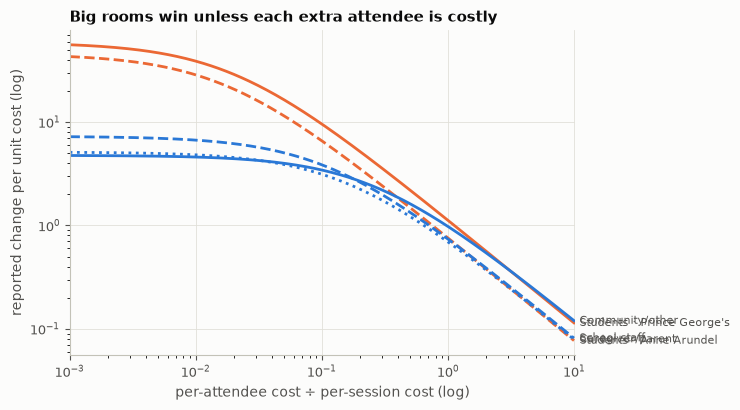

In [27]:
if TARGETING_READY:
    # fig 7: change per unit cost vs per-attendee cost ratio
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    LS = {"Students · Prince George's": "-", "Students · Anne Arundel": "--", "Community/other": "-", "School staff": "--", "Caregiver/parent": ":"}
    for a in val:
        c = ORANGE if a.startswith("Students") else BLUE
        ax.plot(R, val[a], color=c, lw=2, ls=LS.get(a, "-"))
        ax.annotate(a, (R[-1], val[a].iloc[-1]), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=INK2)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(R[0], R[-1] * 1.02)
    ax.grid(True, color=GRID, lw=0.6, which="major")
    style(ax, "Big rooms win unless each extra attendee is costly",
          "per-attendee cost ÷ per-session cost (log)", "reported change per unit cost (log)")
    save(fig, "fig7_reach_by_cost.png")
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 46).")

**Interpretation:** Rankings reflect reported change and attendance under the stated costs. They are not causal estimates. Thin audiences and overlapping intervals require caution.

## A3. Intake tool: predict a group's upside from one question
**Question:** *"How well can you describe 988 and how it works?"* (1 = not at all … 5 = very well), asked **before** the training.
Chosen a priori (it is the training's core content) rather than picked as the best of the three.
Lookup = mean reported change among past attendees who gave each answer. It matched ridge with demographics in A1, so the simplest model wins.

In [28]:
if TARGETING_READY:
    lookup = tg.fit_intake(t)
    ladder = t.groupby(tg.INTAKE).agg(n=("gain", "size"), change=("gain", "mean"), se=("gain", "sem"), change_other_items=("gain_cross", "mean"))
    ladder["lo"], ladder["hi"] = ladder.change - 1.96 * ladder.se, ladder.change + 1.96 * ladder.se
    print(ladder.drop(columns="se").round(2).to_string())
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 49).")

                n  change  change_other_items    lo    hi
pre_describe                                             
1.0           122    1.92                1.50  1.70  2.14
2.0           240    1.56                1.22  1.47  1.64
3.0           330    0.88                0.70  0.81  0.95
4.0           422    0.48                0.49  0.42  0.55
5.0           182    0.02                0.17 -0.08  0.13


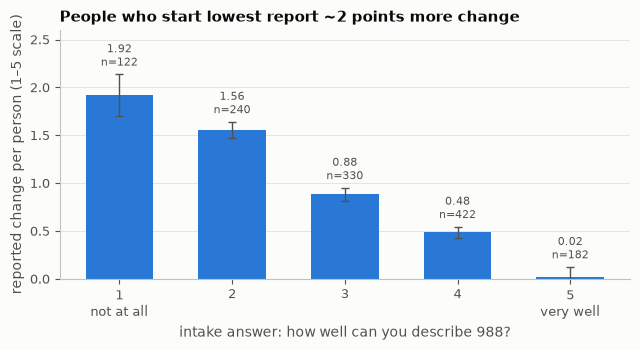

In [29]:
if TARGETING_READY:
    # fig 8: expected change by intake answer
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    x = ladder.index.astype(int)
    ax.bar(x, ladder.change, width=0.6, color=BLUE)
    ax.errorbar(x, ladder.change, yerr=1.96 * ladder.se, fmt="none", ecolor=INK2, lw=1, capsize=3)
    for xi, (v, n) in zip(x, zip(ladder.change, ladder.n)):
        ax.annotate(f"{v:.2f}\nn={n}", (xi, v + 1.96 * ladder.se.loc[xi] + 0.05), ha="center", va="bottom", fontsize=8, color=INK2)
    ax.set_xticks(x, ["1\nnot at all", "2", "3", "4", "5\nvery well"])
    ax.set_ylim(0, 2.6); ax.grid(True, axis="y", color=GRID, lw=0.6); ax.set_axisbelow(True)
    style(ax, "People who start lowest report ~2 points more change", "intake answer: how well can you describe 988?", "reported change per person (1–5 scale)")
    save(fig, "fig8_intake_ladder.png")
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 50).")

In [30]:
if TARGETING_READY:
    # using the tool: three made-up groups of 30 (one intake answer per attendee)
    groups = {"mostly unaware": [1]*10 + [2]*12 + [3]*6 + [4]*2,
              "mixed":          [1]*3 + [2]*6 + [3]*9 + [4]*9 + [5]*3,
              "already aware":  [3]*4 + [4]*14 + [5]*12}
    print(pd.DataFrame({k: tg.score_group(v, lookup) for k, v in groups.items()}).round(2).to_string())
    # and on the real audiences: the tool's expected total per session vs what was reported
    s = t.groupby("session").agg(audience=("audience", "first"), actual=("gain", "sum"),
                                 expected=(tg.INTAKE, lambda a: tg.score_group(list(a), lookup)["expected total change"]))
    print(); print(s.groupby("audience")[["actual", "expected"]].mean().round(1).to_string())
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 51).")

                                      mostly unaware  mixed  already aware
attendees                                      30.00  30.00          30.00
expected change per person                      1.47   0.92           0.35
expected total change                          44.16  27.48          10.58
low-knowledge attendees (answer 1-2)           22.00   9.00           0.00

                            actual  expected
audience                                    
Caregiver/parent               5.1       5.3
Community/other                4.8       4.1
School staff                   7.3       7.4
Students · Anne Arundel       45.6      47.9
Students · Montgomery          2.0       2.1
Students · Prince George's    58.9      52.3
Students · Queen Anne's        8.0       8.0


**Interpretation:** The intake lookup is a retrospective association. Collect a true pre-training intake item and validate the lookup before using it for allocation.

# Part B — Evidence base
The sections below are the full survey analysis that Part A builds on.

# 1. What's in the data (and what changed over the year)
- who: roles × county. sessions = training date × county.
- the survey **changed during the year**: some questions only exist in some months. need to know this before comparing anything.

In [31]:
print("responses", len(d), "| dated sessions", d.dropna(subset=["training_date"]).session.nunique(), "| dates", d.training_date.dropna().min(), "→", d.training_date.dropna().max(), "| missing date", d.training_date.isna().sum())
print(pd.crosstab(d.county, d.role, margins=True))
print(d.language.value_counts().to_dict())

responses 1299 | dated sessions 54 | dates 2025-10-21 → 2026-10-21 | missing date 3
role             Caregiver/parent  Community/other  Multiple roles  School staff  Student   All
county                                                                                         
Anne Arundel                    2                5               4            39      887   937
Fairfax                         0                3               1             2        0     6
Harris                          0                1               0             0        0     1
Montgomery                      6               22               3             0        3    34
Prince George's                43               58               6            22      180   309
Queen Anne's                    6                0               0             0        6    12
All                            57               89              14            63     1076  1299
{'English': 1280, 'Spanish': 19}


In [32]:
# question coverage by month: % of responses with an answer
COVER = {"Knowledge (after)": "post_when", "Satisfaction": "sat_engaged", "Recommend 0–10": "recommend",
         "Call 988 0–10": "call", "Comment: valuable": "valuable_len", "Comment: improve": "improve_len"}
cov = pd.DataFrame({k: d.groupby("month")[c].apply(lambda s: ((s > 0) if c.endswith("_len") else s.notna()).mean() * 100) for k, c in COVER.items()}).T
n_month = d.groupby("month").size()
print(cov.round(0).astype(int).to_string())
print(n_month.to_dict())

month              2025-10  2025-11  2025-12  2026-01  2026-02  2026-03  2026-04  2026-05  2026-06  2026-07  2026-08  2026-09  2026-10
Knowledge (after)      100      100      100      100      100      100      100      100      100      100      100      100      100
Satisfaction           100      100      100      100      100       87       98       97       96       86      100       99       53
Recommend 0–10         100      100      100       98      100       80       96       93       96       86      100      100      100
Call 988 0–10            0        0        0        0        0        3        6       66       96       86      100        1       43
Comment: valuable       75       86       72       90       78       77       86       78       93       71       75       86       75
Comment: improve        46       29       58       76       56       60       70       70       85       43       75       40       20
{'2025-10': 28, '2025-11': 7, '2025-12': 36, '2026-01':

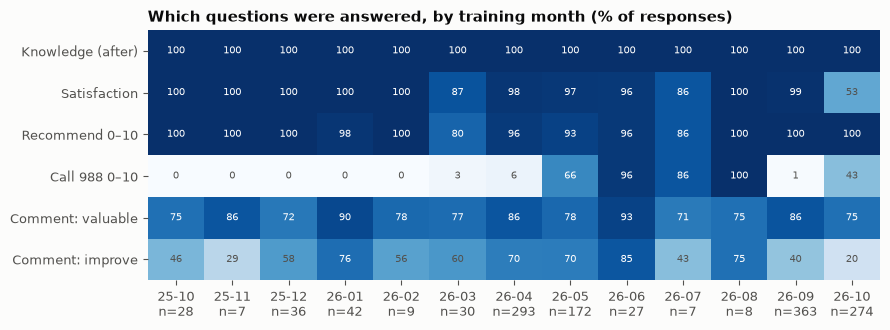

In [33]:
if cov.shape[1] > 0:
    # fig 1: coverage heatmap
    fig, ax = plt.subplots(figsize=(9, 3.4))
    im = ax.imshow(cov.to_numpy(), cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(cov.shape[1]), [f"{m[2:4]}-{m[5:]}\nn={n_month[m]}" for m in cov.columns], fontsize=7.5)
    ax.set_yticks(range(cov.shape[0]), cov.index, fontsize=9)
    for i in range(cov.shape[0]):
        for j in range(cov.shape[1]):
            v = cov.iat[i, j]; ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 60 else INK2)
    style(ax, "Which questions were answered, by training month (% of responses)")
    for s in ax.spines.values(): s.set_visible(False)
    save(fig, "fig1_coverage.png")
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 57).")

**Interpretation:** Coverage shows observed answers, not confirmed form versions. Zero is a valid 0–10 answer and counts as answered. Use the inferred-availability statuses and actual form metadata when interpreting changes over time.

In [34]:
# which sessions are which version
v = d.groupby("session").agg(n=("id", "size"), sat_asked=("sat_engaged", lambda s: s.notna().mean()), call_asked=("call", lambda s: s.notna().mean()))
print(v[(v.n >= 30)].round(2).sort_index().to_string())

                                n  sat_asked  call_asked
session                                                 
2026-01-22 | Prince George's   31       1.00        0.00
2026-04-14 | Anne Arundel      31       0.97        0.00
2026-04-15 | Anne Arundel      30       1.00        0.00
2026-04-15 | Prince George's   60       1.00        0.02
2026-04-27 | Anne Arundel      39       0.90        0.00
2026-04-28 | Anne Arundel      38       1.00        0.00
2026-04-30 | Anne Arundel      60       0.98        0.00
2026-05-01 | Anne Arundel      52       1.00        0.02
2026-05-13 | Prince George's  104       0.94        0.93
2026-09-01 | Anne Arundel      54       0.98        0.02
2026-09-02 | Anne Arundel      51       1.00        0.00
2026-09-28 | Anne Arundel     143       0.99        0.00
2026-09-29 | Anne Arundel     115       1.00        0.01
2026-10-05 | Anne Arundel      33       1.00        0.00
2026-10-08 | Anne Arundel      74       0.91        0.00
2026-10-09 | Anne Arundel      

# 2. Did people report learning? (pre vs post)
null: after and before ratings are the same. alt: they differ. paired data → **Wilcoxon signed-rank** (ordinal 1–5, not normal).
also look at *who could even improve*: anyone who rated "before" = 5 is at the ceiling.

In [35]:
rows = []
for k, label in ITEMS.items():
    pre, post, g = d[f"pre_{k}"], d[f"post_{k}"], d[f"gain_{k}"]
    paired = pre.notna() & post.notna()
    pre, post, g = pre[paired], post[paired], g[paired]
    pvalue = stats.wilcoxon(post, pre).pvalue if len(g) and g.ne(0).any() else (1.0 if len(g) else np.nan)
    rows.append({"item": label, "n": g.notna().sum(), "agree before %": (pre >= 4).mean() * 100, "agree after %": (post >= 4).mean() * 100,
                 "mean change": g.mean(), "higher %": (g > 0).mean() * 100, "same %": (g == 0).mean() * 100, "lower %": (g < 0).mean() * 100,
                 "before = 5 %": (pre == 5).mean() * 100, "change if before ≤ 3": g[pre <= 3].mean(), "wilcoxon p": pvalue})
learn = pd.DataFrame(rows).set_index("item")
print(learn.round({c: 2 for c in learn if c != "wilcoxon p"}).to_string(formatters={"wilcoxon p": "{:.1e}".format}))
print("agree on all 3 after: %.1f%%" % ((d[POST].dropna() >= 4).all(axis=1).mean() * 100))

                         n  agree before %  agree after %  mean change  higher %  same %  lower %  before = 5 %  change if before ≤ 3 wilcoxon p
item                                                                                                                                            
Identify crises       1299           72.21          89.92         0.46     43.96   51.42     4.62         18.09                  1.12    3.7e-73
Describe 988          1299           46.50          90.45         1.11     66.28   29.48     4.23         14.01                  1.86   8.2e-124
Know when to use 988  1299           55.66          92.30         1.01     58.43   37.57     4.00         21.63                  1.97   1.5e-109
agree on all 3 after: 84.5%


In [36]:
# same thing split by student vs nonstudent (agree %, before → after)
by = d.groupby("group").agg(**{f"{k}_{t}": (f"{t}_{k}", lambda s: (s.dropna() >= 4).mean() * 100) for k in ITEMS for t in ["pre", "post"]}, n=("id", "size"))
print(by.round(1).T.to_string())
for k in ITEMS:
    print(k, "mean change student %.2f nonstudent %.2f" % tuple(d.groupby("group")[f"gain_{k}"].mean().reindex(GROUPS)),
          "| mann-whitney p = %.2g" % stats.mannwhitneyu(d.loc[d.group == "Student", f"gain_{k}"].dropna(), d.loc[d.group == "Nonstudent", f"gain_{k}"].dropna()).pvalue)

group          Nonstudent  Student
identify_pre         74.4     71.8
identify_post        91.8     89.5
describe_pre         43.8     47.0
describe_post        91.3     90.3
when_pre             46.1     57.6
when_post            93.2     92.1
n                   219.0   1080.0
identify mean change student 0.47 nonstudent 0.42 | mann-whitney p = 0.92
describe mean change student 1.06 nonstudent 1.39 | mann-whitney p = 0.0026
when mean change student 0.92 nonstudent 1.44 | mann-whitney p = 1.3e-06


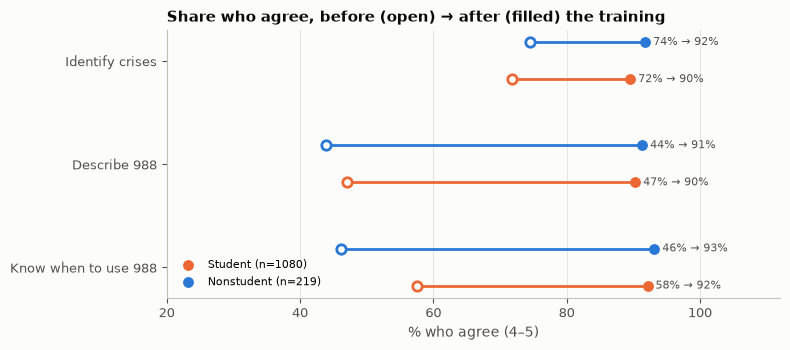

In [37]:
if KNOWN_GROUPS:
    # fig 2: before → after agree %, by item and group
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for gi, grp in enumerate(["Student", "Nonstudent"]):
        for i, k in enumerate(ITEMS):
            y = i + (0.18 if grp == "Student" else -0.18)
            a, b = by.loc[grp, f"{k}_pre"], by.loc[grp, f"{k}_post"]
            ax.plot([a, b], [y, y], color=GROUP_COLOR[grp], lw=2, zorder=1)
            ax.scatter([a], [y], s=46, facecolor=SURF, edgecolor=GROUP_COLOR[grp], lw=2, zorder=2)
            ax.scatter([b], [y], s=46, color=GROUP_COLOR[grp], zorder=2, label=f"{grp} (n={by.loc[grp, 'n']})" if i == 0 else None)
            ax.text(b + 1.2, y, f"{a:.0f}% → {b:.0f}%", va="center", fontsize=8, color=INK2)
    ax.set_yticks(range(3), ITEMS.values()); ax.invert_yaxis(); ax.set_xlim(20, 112)
    ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
    style(ax, "Share who agree, before (open) → after (filled) the training", "% who agree (4–5)")
    ax.legend(frameon=False, fontsize=8, loc="lower left")
    save(fig, "fig2_before_after.png")
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 63).")

**Interpretation:** Use paired-valid denominators above. Ceiling effects limit improvement for high baseline ratings; all changes remain retrospective self-report.

In [38]:
# who reports going DOWN after training? (lower after on at least one item)
dec = (d[GAIN] < 0).any(axis=1)
print("any lower:", dec.sum(), "| of those, discordant response pattern:", (dec & (d.flag_scale_misread == 1)).sum())
a = d[d.flag_scale_misread == 1]
print("discordant response pattern n=%d | mean before %.2f | recommend mean %.1f (n=%d) | rec ≥ 9: %d | all 3 sat items ≥ 4: %d" % (
    len(a), a[PRE].mean(axis=1).mean(), a.recommend.mean(), a.recommend.notna().sum(), (a.recommend >= 9).sum(), (a[SAT] >= 4).all(axis=1).sum()))

any lower: 108 | of those, discordant response pattern: 8
discordant response pattern n=10 | mean before 3.13 | recommend mean 9.4 (n=10) | rec ≥ 9: 9 | all 3 sat items ≥ 4: 10


**Interpretation:** The flagged pattern is descriptive, not proof of a scale misread or invalid response. Keep these records in the default analysis and inspect sensitivity results.

# 3. Student/nonstudent recommendation comparisons
Student means anyone who selected Student, including multiple roles. Nonstudent means a completely mapped role response without Student; unknown memberships are excluded from this comparison.
Compare scores within county using Mann–Whitney U; differences are associations, not causal effects.

In [39]:
if COUNTY_READY:
    two = d[d.county.isin(["Anne Arundel", "Prince George's"])]
    rows = []
    for (c, g), s in two.groupby(["county", "group"]):
        r = s.recommend.dropna(); lo, hi = boot_ci(r)
        rows.append({"county": c, "group": g, "n": len(r), "mean": r.mean(), "NPS": nps(r), "NPS 95% CI": f"[{lo:.0f}, {hi:.0f}]",
                     "detractor %": (r <= 6).mean() * 100, "promoter %": (r >= 9).mean() * 100})
    gap = pd.DataFrame(rows).set_index(["county", "group"])
    print(gap.round(1).to_string())
    for c in ["Anne Arundel", "Prince George's"]:
        s = two[two.county == c]
        print(c, "students vs nonstudents mann-whitney p = %.2g" % stats.mannwhitneyu(s.loc[s.group == "Student", "recommend"].dropna(), s.loc[s.group == "Nonstudent", "recommend"].dropna()).pvalue)
    st = d[d.group == "Student"]
    print("students AA vs PG mann-whitney p = %.2g" % stats.mannwhitneyu(st.loc[st.county == "Anne Arundel", "recommend"].dropna(), st.loc[st.county == "Prince George's", "recommend"].dropna()).pvalue)
    print("student satisfaction means by county:", st[st.county.isin(["Anne Arundel", "Prince George's"])].groupby("county")[SAT].mean().round(2).to_dict("index"))
    print("NPS by role:", d.groupby("role").recommend.agg(nps).round(0).to_dict(), "| n:", d.groupby("role").recommend.count().to_dict())
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 68).")

                              n  mean   NPS NPS 95% CI  detractor %  promoter %
county          group                                                          
Anne Arundel    Nonstudent   50   9.4  78.0   [66, 90]          0.0        78.0
                Student     873   7.0  -9.6  [-15, -5]         38.1        28.5
Prince George's Nonstudent  122   9.4  79.5   [70, 88]          3.3        82.8
                Student     169   8.3  39.1   [28, 50]         14.8        53.8
Anne Arundel students vs nonstudents mann-whitney p = 7.1e-16
Prince George's students vs nonstudents mann-whitney p = 8.6e-09
students AA vs PG mann-whitney p = 2.5e-13
student satisfaction means by county: {'Anne Arundel': {'sat_engaged': 4.27, 'sat_knew': 4.38, 'sat_organized': 4.41}, "Prince George's": {'sat_engaged': 4.25, 'sat_knew': 4.44, 'sat_organized': 4.47}}
NPS by role: {'Caregiver/parent': 75.0, 'Community/other': 80.0, 'Multiple roles': 93.0, 'School staff': 82.0, 'Student': -2.0} | n: {'Caregiver/par

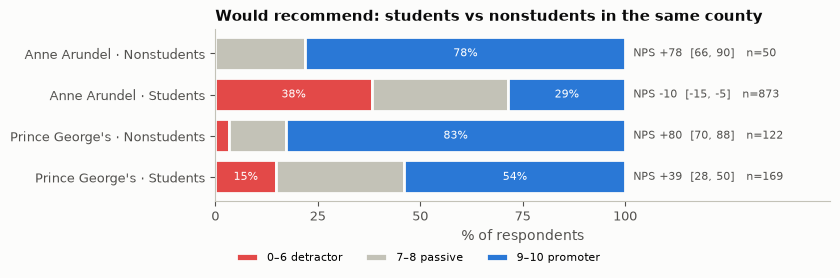

In [40]:
if COUNTY_READY:
    # fig 3: detractor / passive / promoter stacks, students vs nonstudents within county
    fig, ax = plt.subplots(figsize=(8.5, 3.2))
    labels = []
    for i, ((c, g), r) in enumerate(gap.iterrows()):
        det, pro = r["detractor %"], r["promoter %"]; pas = 100 - det - pro
        ax.barh(i, det, color=RED, edgecolor=SURF, lw=2); ax.barh(i, pas, left=det, color=GRAY, edgecolor=SURF, lw=2); ax.barh(i, pro, left=det + pas, color=BLUE, edgecolor=SURF, lw=2)
        for left, w in [(0, det), (det + pas, pro)]:
            if w >= 8: ax.text(left + w / 2, i, f"{w:.0f}%", ha="center", va="center", color="white", fontsize=8)  # skip slivers
        ax.text(102, i, f"NPS {r['NPS']:+.0f}  {r['NPS 95% CI']}   n={r['n']}", va="center", fontsize=8, color=INK2)
        labels.append(f"{c} · {g}s")
    ax.set_yticks(range(len(labels)), labels); ax.invert_yaxis(); ax.set_xlim(0, 150); ax.set_xticks(range(0, 101, 25))
    style(ax, "Would recommend: students vs nonstudents in the same county", "% of respondents")
    ax.legend(["0–6 detractor", "7–8 passive", "9–10 promoter"], ncol=3, frameon=False, fontsize=8, loc="lower center", bbox_to_anchor=(0.33, -0.42))
    save(fig, "fig3_student_gap.png")
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 69).")

**notes**
- gap holds **inside** both counties → it isn't just "Anne Arundel is different".
- but students in Prince George's are way more positive than students in Anne Arundel. so county (or something about those schools/sessions) matters *too*.

## 3b. Do students just like the training less?
if students recommend less because they liked it less, then students and nonstudents who gave the **same satisfaction ratings** should recommend about the same. check by satisfaction level.

In [41]:
if SAT_READY:
    d["sat_band"] = pd.cut(d.sat_mean, [0, 3.99, 4.67, 5], labels=["< 4 (not all agree)", "4 – 4.67", "4.67 – 5 (near-perfect)"])
    rows = []
    for (b, g), s in d.groupby(["sat_band", "group"], observed=True):
        r = s.recommend.dropna(); lo, hi = boot_ci(r)
        rows.append({"satisfaction": b, "group": g, "n": len(r), "NPS": nps(r), "lo": lo, "hi": hi, "mean": r.mean()})
    satgap = pd.DataFrame(rows)
    print(satgap.round(1).to_string(index=False))
    top = d[d.sat_band == "4.67 – 5 (near-perfect)"]
    print("near-perfect satisfaction, students vs nonstudents mann-whitney p = %.2g" % stats.mannwhitneyu(top.loc[top.group == "Student", "recommend"].dropna(), top.loc[top.group == "Nonstudent", "recommend"].dropna()).pvalue)
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 71).")

           satisfaction      group   n   NPS    lo    hi  mean
    < 4 (not all agree) Nonstudent  12  50.0  25.0  75.0   8.8
    < 4 (not all agree)    Student 123 -39.0 -52.8 -23.6   6.2
               4 – 4.67 Nonstudent  64  54.7  40.6  68.8   8.7
               4 – 4.67    Student 439  -3.6 -10.7   3.9   7.2
4.67 – 5 (near-perfect) Nonstudent 139  93.5  88.5  97.8   9.7
4.67 – 5 (near-perfect)    Student 354  14.7   6.5  23.2   7.7
near-perfect satisfaction, students vs nonstudents mann-whitney p = 1.7e-29


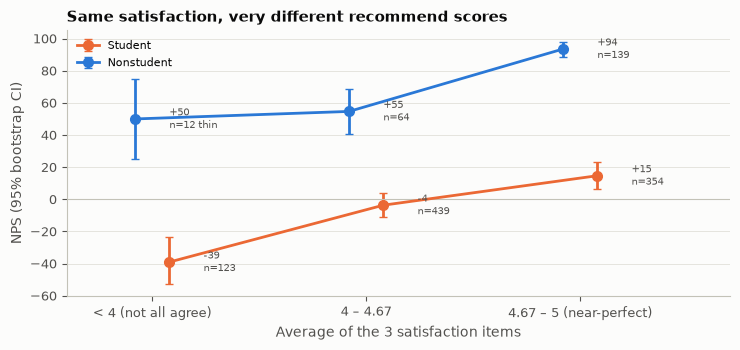

In [42]:
if SAT_READY:
    # fig 4: nps by satisfaction band
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    bands = list(d.sat_band.cat.categories)
    for g, off in [("Student", 0.08), ("Nonstudent", -0.08)]:
        s = satgap[satgap.group == g].set_index("satisfaction").reindex(bands)
        x = np.arange(len(bands)) + off
        ax.errorbar(x, s.NPS, yerr=[s.NPS - s.lo, s.hi - s.NPS], fmt="o-", color=GROUP_COLOR[g], lw=2, ms=7, capsize=3, label=g)
        for xi, (_, r) in zip(x, s.iterrows()):
            ax.text(xi + 0.16, r.NPS, f"{r.NPS:+.0f}\nn={r.n:.0f}" + (" thin" if r.n < THIN else ""), fontsize=7.5, color=INK2, va="center")
    ax.axhline(0, color=GRAY, lw=0.8); ax.set_xticks(range(len(bands)), bands); ax.set_xlim(-0.4, 2.7)
    ax.yaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
    style(ax, "Same satisfaction, very different recommend scores", "Average of the 3 satisfaction items", "NPS (95% bootstrap CI)")
    ax.legend(frameon=False, fontsize=8)
    save(fig, "fig4_nps_by_satisfaction.png")
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 72).")

In [43]:
if COUNTY_READY and SAT_READY and has_data(["recommend", "sat_mean", "post_mean", "duration_s", "session"], 30) and d.session.nunique() >= 3:
    # regression: does the student gap survive controls? (AA + PG only, complete cases)
    # recommend ~ student + county + satisfaction + after-knowledge + log survey time; se clustered by session
    m_df = d[d.county.isin(["Anne Arundel", "Prince George's"]) & d.group.isin(GROUPS) & d.duration_s.gt(0) & d.session.notna()].dropna(subset=["recommend", "sat_mean", "post_mean", "duration_s"]).copy()
    m_df["student"] = (m_df.group == "Student").astype(int)
    m_df["sat_c"] = m_df.sat_mean - m_df.sat_mean.mean(); m_df["post_c"] = m_df.post_mean - m_df.post_mean.mean()
    m_df["log_dur"] = np.log(m_df.duration_s)
    model = smf.ols("recommend ~ student + C(county) + sat_c + post_c + log_dur", data=m_df).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(m_df.session)[0]})
    print(model.summary().tables[1]); print("n =", int(model.nobs), "| sessions =", m_df.session.nunique(), "| R² = %.3f" % model.rsquared)
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 73).")

                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                        6.9493      0.457     15.206      0.000       6.054       7.845
C(county)[T.Prince George's]     0.7560      0.247      3.062      0.002       0.272       1.240
student                         -1.3559      0.199     -6.809      0.000      -1.746      -0.966
sat_c                            0.2823      0.144      1.963      0.050       0.000       0.564
post_c                           0.3837      0.125      3.072      0.002       0.139       0.629
log_dur                          0.3861      0.113      3.424      0.001       0.165       0.607
n = 1076 | sessions = 38 | R² = 0.204


**Interpretation:** Interpret the displayed adjusted group gap as an association. Different interpretations of the recommendation question are possible, but cannot be established from this survey.

# 4. Survey conditions: speed, delay, and sessions
student sessions are huge (up to 143 people), and most fast completions (the cleaner's `flag_fast`, < 20 s) are students. survey time could be a sign of how the survey was given (in class, rushed, days later).

In [44]:
if has_data(["recommend", "duration_s", "lag_days", "county"], 3):
    print(pd.crosstab(d.group, d.flag_fast, margins=True))
    print("median survey seconds:", d.groupby("group").duration_s.median().to_dict(), "| median days to respond:", d.groupby("group").lag_days.median().to_dict())
    s_aa = d[(d.group == "Student") & (d.county == "Anne Arundel")].copy()
    s_aa["time"] = pd.cut(s_aa.duration_s, [0, 30, 45, 60, 120, 1e6], labels=["<30s", "30–45s", "45–60s", "1–2 min", "2 min+"])
    print(s_aa.groupby("time", observed=True).recommend.agg(n="count", mean="mean", NPS=nps).round(1).to_string())
    print("AA students: spearman(survey seconds, recommend) =", stats.spearmanr(s_aa.duration_s, s_aa.recommend, nan_policy="omit"))
    s_aa["late"] = pd.cut(s_aa.lag_days, [-2, 7, 14, 100], labels=["≤ 7 days", "8–14", "15+"])
    print(s_aa.groupby("late", observed=True).recommend.agg(n="count", mean="mean", NPS=nps).round(1).to_string())
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 76).")

flag_fast      0   1   All
group                     
Nonstudent   219   0   219
Student     1064  16  1080
All         1283  16  1299
median survey seconds: {'Nonstudent': 106.0, 'Student': 43.0} | median days to respond: {'Nonstudent': 2.0, 'Student': 7.0}
           n  mean   NPS
time                    
<30s     230   6.6 -25.7
30–45s   339   7.0  -9.7
45–60s   157   7.2   0.0
1–2 min  111   7.3   1.8
2 min+    36   7.6  16.7
AA students: spearman(survey seconds, recommend) = SignificanceResult(statistic=np.float64(0.1407153347892787), pvalue=np.float64(3.0130724209980543e-05))
            n  mean   NPS
late                     
≤ 7 days  587   7.2  -4.1
8–14       72   7.1  -6.9
15+       214   6.4 -25.7


In [45]:
if SESSION_READY:
    # session-level: student sessions with ≥ 30 students
    ss = d[d.group == "Student"].groupby("session").agg(n=("id", "size"), county=("county", "first"), NPS=("recommend", nps),
           secs=("duration_s", "median"), fast=("flag_fast", "mean"), lag=("lag_days", "median"), gain=("gain_describe", "mean"))
    big = ss[ss.n >= THIN].sort_values("NPS")
    print(big.round(2).to_string())
    print("spearman(session median seconds, session NPS) =", stats.spearmanr(big.secs, big.NPS))
    # how much of student recommend variance sits between sessions? random-intercept model
    mix = smf.mixedlm("recommend ~ 1", STUDENT_SESSIONS, groups="session").fit()
    icc = mix.cov_re.iloc[0, 0] / (mix.cov_re.iloc[0, 0] + mix.scale)
    print("ICC (share of student recommend variance between sessions) = %.3f" % icc)
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 77).")

                                n           county    NPS   secs  fast   lag  gain
session                                                                           
2026-04-14 | Anne Arundel      31     Anne Arundel -68.97   45.0   0.0  20.0  1.23
2026-10-08 | Anne Arundel      74     Anne Arundel -29.73   38.0   0.0  16.0  1.07
2026-04-28 | Anne Arundel      38     Anne Arundel -27.78   44.0   0.0   6.0  1.37
2026-04-15 | Anne Arundel      30     Anne Arundel -23.33   46.5   0.0  19.0  1.70
2026-09-28 | Anne Arundel     143     Anne Arundel -18.88   35.0  0.02   8.0  1.28
2026-10-09 | Anne Arundel      48     Anne Arundel -16.67   33.0  0.02  16.0  0.69
2026-10-21 | Anne Arundel      57     Anne Arundel -15.79   33.0  0.05   0.0  0.72
2026-04-27 | Anne Arundel      39     Anne Arundel -14.71   40.0   0.0   7.0  0.87
2026-05-01 | Anne Arundel      52     Anne Arundel  -8.33   40.0   0.0   5.0  1.17
2026-09-01 | Anne Arundel      54     Anne Arundel   0.00   44.0   0.0   7.0  0.59
2026

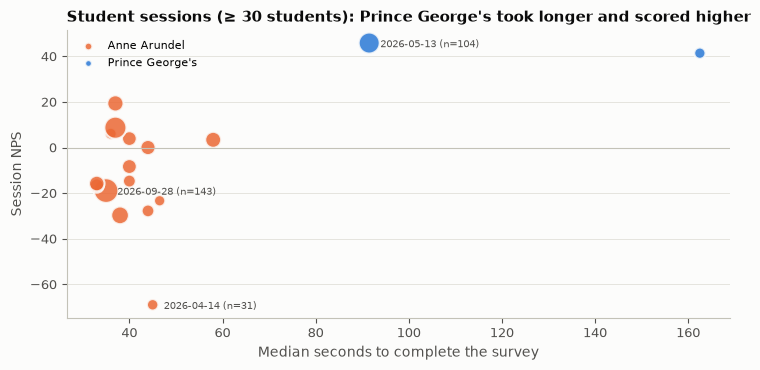

In [46]:
if SESSION_READY:
    # fig 5: student sessions, nps vs median survey time
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    cc = {"Anne Arundel": ORANGE, "Prince George's": BLUE}
    for c, s in big.groupby("county"):
        ax.scatter(s.secs, s.NPS, s=s.n * 2.2, color=cc.get(c, GRAY), alpha=0.85, edgecolor=SURF, lw=1.5, label=c)
    for name, r in big.iterrows():
        if r.NPS == big.NPS.min() or r.NPS == big.NPS.max() or r.n == big.n.max():
            ax.annotate(f"{name.split(' |')[0]} (n={r.n})", (r.secs, r.NPS), xytext=(8, -3), textcoords="offset points", fontsize=7.5, color=INK2)
    ax.axhline(0, color=GRAY, lw=0.8); ax.yaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
    style(ax, "Student sessions (≥ 30 students): Prince George's took longer and scored higher", "Median seconds to complete the survey", "Session NPS")
    ax.legend(frameon=False, fontsize=8, markerscale=0.4, loc="upper left")
    save(fig, "fig5_sessions.png")
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 78).")

**Interpretation:** Person-level timing associations and between-session associations answer different questions. These do not establish why survey conditions differ or that timing caused recommendation differences.

# 5. Open-ended comments (keyword themes)
*nothing* (`i_none`) and *asked a question* (`i_question`) are the cleaner's own fields (comment category = none stated; comment contains "?"). topic themes are keyword rules on the comment text from `private`, counted in memory. not hand-checked → leads.
test students vs nonstudents on each theme: **Fisher's exact** (some counts are small).

In [47]:
V = [c for c in d if c.startswith("v_")]; I = [c for c in d if c.startswith("i_")]
for name, length, cols in [("most valuable", "valuable_len", V), ("improve", "improve_len", I)]:
    c = d[d[length] > 0]
    print(f"\n== {name}: {len(c)} commenters | share who commented:", d.groupby("group")[length].apply(lambda s: (s > 0).mean() * 100).round(1).to_dict())
    rows = []
    for t in cols:
        ct = pd.crosstab(c.group, c[t]).reindex(index=GROUPS, columns=[0, 1], fill_value=0)
        rows.append({"theme": t, "students %": c.loc[c.group == "Student", t].mean() * 100, "nonstudents %": c.loc[c.group == "Nonstudent", t].mean() * 100,
                     "n yes": int(c[t].sum()), "fisher p": stats.fisher_exact(ct.to_numpy())[1]})
    print(pd.DataFrame(rows).set_index("theme").round(3).sort_values("n yes", ascending=False).to_string())


== most valuable: 1063 commenters | share who commented: {'Nonstudent': 81.7, 'Student': 81.9}
                    students %  nonstudents %  n yes  fisher p
theme                                                         
v_when                  13.009          8.380    130     0.103
v_anyone                12.670          3.352    118     0.000
v_not_only_suicide       5.995          5.587     63     1.000
v_confidential           6.109          4.469     62     0.486
v_vs_911                 1.584         10.615     33     0.000
v_how_works              2.036          5.587     28     0.017
v_signs                  2.715          1.676     27     0.603

== improve: 651 commenters | share who commented: {'Nonstudent': 60.7, 'Student': 48.0}
               students %  nonstudents %  n yes  fisher p
theme                                                    
i_question         33.977          0.752    177     0.000
i_none              8.880         12.782     63     0.189
i_more_time     

In [48]:
# does what people wrote line up with how they scored? (recommend, among commenters)
for t, length in [("i_question", "improve_len"), ("i_interactive", "improve_len"), ("i_none", "improve_len"), ("v_when", "valuable_len")]:
    c = d[(d[length] > 0) & (d.group == "Student")]
    print(t, "students | theme yes: n=%d NPS %+.0f | no: n=%d NPS %+.0f" % ((c[t] == 1).sum(), nps(c.loc[c[t] == 1, "recommend"]), (c[t] == 0).sum(), nps(c.loc[c[t] == 0, "recommend"])))

i_question students | theme yes: n=176 NPS +2 | no: n=342 NPS +16
i_interactive students | theme yes: n=19 NPS +61 | no: n=499 NPS +9
i_none students | theme yes: n=46 NPS -13 | no: n=472 NPS +13
v_when students | theme yes: n=115 NPS +0 | no: n=769 NPS +5


In [49]:
# what are students asking about? keyword sub-themes inside "asked a question" (counts only, no text)
import re
qs = private[["response_id", "improve"]].set_axis(["id", "text"], axis=1).merge(d[["id", "i_question", "group"]], on="id")
qs = qs[(qs.i_question == 1)].text.fillna("").str.lower()
SUB = {"how many / how often (scale of 988)": r"how many|how much|how often|percent|statistic|number of|per (day|minute|year)",
       "what happens on a call / who answers": r"what happens|who (answers|picks|is on)|how (does|do) (it|they|988|the)|wait|how long|counselor|volunteer|after (you|i) call",
       "can I call if... (eligibility)": r"(can|could|should) (i|you|we|someone) (call|text|use)|only (for|if)|just (worried|sad|stressed)|is it (ok|okay)|allowed|what if",
       "privacy / parents / police": r"histor|parent|private|anonym|confiden|trace|track|record|police|location",
       "helping a friend": r"friend|someone else|for (someone|others)|help (a|my|someone|others)"}
import warnings; warnings.filterwarnings("ignore", "This pattern is interpreted")  # groups are for alternation only
sub = pd.Series({k: int(qs.str.contains(p).sum()) for k, p in SUB.items()})
print(sub.to_string()); print("questions matched by none of these:", int((~pd.concat([qs.str.contains(p) for p in SUB.values()], axis=1).any(axis=1)).sum()), "of", len(qs))
del qs  # comment text stays out of the rest of the notebook

how many / how often (scale of 988)     29
what happens on a call / who answers    18
can I call if... (eligibility)          21
privacy / parents / police               6
helping a friend                         4
questions matched by none of these: 104 of 177


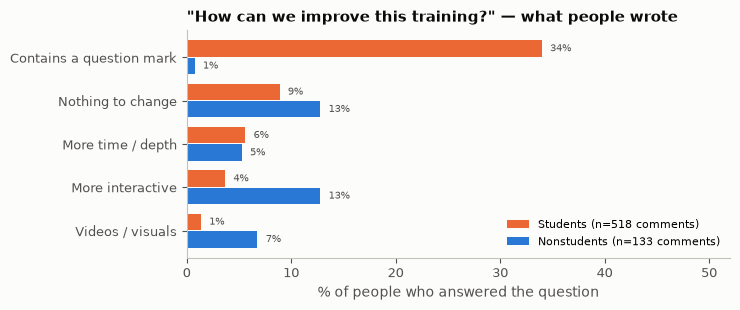

In [50]:
if COMMENTS_READY:
    # fig 6: improve themes, students vs nonstudents (share of people who wrote an improve comment)
    c = d[d.improve_len > 0]
    names = {"i_question": "Contains a question mark", "i_none": "Nothing to change", "i_interactive": "More interactive", "i_more_time": "More time / depth", "i_media": "Videos / visuals"}
    tab = (c.groupby("group")[list(names)].mean() * 100).T.rename(index=names).sort_values("Student")
    nn = c.group.value_counts()
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    y = np.arange(len(tab))
    for g, off in [("Student", 0.2), ("Nonstudent", -0.2)]:
        ax.barh(y + off, tab[g], height=0.38, color=GROUP_COLOR[g], label=f"{g}s (n={nn[g]} comments)")
        for yi, v in zip(y + off, tab[g]): ax.text(v + 0.8, yi, f"{v:.0f}%", va="center", fontsize=7.5, color=INK2)
    ax.set_yticks(y, tab.index); ax.set_xlim(0, 52)
    style(ax, "\"How can we improve this training?\" — what people wrote", "% of people who answered the question")
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    save(fig, "fig6_improve_themes.png")
else:
    print("Skipped analysis: required fields, groups, or sufficient sessions are unavailable (section cell 84).")

**Interpretation:** Question-mark and keyword indicators are unvalidated annotations. Inspect the computed counts and privately validate a stratified English/Spanish sample before recommending changes.

# 6. Do the data-quality choices change the answers? (sensitivity)
rerun the headline numbers dropping each of the cleaner's flagged groups, then all of them.

In [51]:
def headline(x):
    s = x[x.group == "Student"]; a = x[x.group == "Nonstudent"]
    return {"n": len(x), "agree all 3 after %": (x[POST].dropna() >= 4).all(axis=1).mean() * 100, "mean change describe": x.gain_describe.mean(),
            "NPS all": nps(x.recommend), "NPS students": nps(s.recommend), "NPS nonstudents": nps(a.recommend)}
FLAGS = {"fast (< 20 s)": "flag_fast", "straight-lining": "flag_straightline", "discordant response pattern": "flag_scale_misread"}
sens = {"keep everyone (default)": headline(d)}
for k, f in FLAGS.items(): sens[f"drop {k}"] = headline(d[d[f].ne(1).fillna(True)])
sens["drop all flagged"] = headline(d[d[list(FLAGS.values())].ne(1).fillna(True).all(axis=1)])
sens = pd.DataFrame(sens).T
print(sens.round(1).to_string())

                                       n  agree all 3 after %  mean change describe  NPS all  NPS students  NPS nonstudents
keep everyone (default)           1299.0                 84.5                   1.1     12.0          -1.8             79.5
drop fast (< 20 s)                1283.0                 84.7                   1.1     12.6          -1.4             79.5
drop straight-lining              1207.0                 85.0                   1.2     12.5          -0.5             82.6
drop discordant response pattern  1289.0                 85.2                   1.1     11.5          -1.8             78.7
drop all flagged                  1183.0                 86.0                   1.2     12.4          -0.1             81.8


**Interpretation:** Compare the sensitivity table above; definitions and group membership are explicit. Unassessable quality flags are retained when dropping flagged responses.

# 7. Smaller things
- *call 988* (only asked in some versions)
- Spanish-language responses
- months / time trend for students

In [52]:
c = d.dropna(subset=["call"])
print("call answered:", len(c), "| by group:", c.group.value_counts().to_dict(), "| months:", c.month.value_counts().sort_index().to_dict())
print("call mean by group:", c.groupby("group").call.mean().round(2).to_dict(), "| % 9–10:", c.groupby("group").call.apply(lambda s: (s >= 9).mean() * 100).round(1).to_dict())
print("spearman call vs recommend %.2f | call vs know-when-after %.2f" % (stats.spearmanr(c.call, c.recommend, nan_policy="omit")[0], stats.spearmanr(c.call, c.post_when)[0]))
sp = d[d.language == "Spanish"]
print("\nspanish n=%d (thin) | roles %s | counties %s" % (len(sp), sp.role.value_counts().to_dict(), sp.county.value_counts().to_dict()))
print("spanish mean change describe %.2f vs english %.2f | agree all 3 after %.0f%% vs %.0f%%" % (sp.gain_describe.mean(), d[d.language == "English"].gain_describe.mean(),
      (sp[POST] >= 4).all(axis=1).mean() * 100, (d[d.language == "English"][POST] >= 4).all(axis=1).mean() * 100))
print("\nstudent NPS by month:"); print(d[d.group == "Student"].groupby("month").recommend.agg(n="count", NPS=nps).round(0).query("n >= 30").to_string())

call answered: 293 | by group: {'Student': 253, 'Nonstudent': 40} | months: {'2026-03': 1, '2026-04': 18, '2026-05': 114, '2026-06': 26, '2026-07': 6, '2026-08': 8, '2026-09': 2, '2026-10': 117}
call mean by group: {'Nonstudent': 9.5, 'Student': 7.37} | % 9–10: {'Nonstudent': 85.0, 'Student': 41.1}
spearman call vs recommend 0.60 | call vs know-when-after 0.22

spanish n=19 (thin) | roles {'Caregiver/parent': 10, 'Student': 6, 'Multiple roles': 2, 'Community/other': 1} | counties {"Queen Anne's": 12, "Prince George's": 7}
spanish mean change describe 0.47 vs english 1.12 | agree all 3 after 84% vs 85%

student NPS by month:
           n   NPS
month             
2026-04  226 -12.0
2026-05  147  28.0
2026-09  363  -4.0
2026-10  274  -9.0


**Interpretation:** Report call-intent coverage and available sample sizes. Language and monthly comparisons can be confounded by role, county, and form availability.

# 8. Limits
- **retrospective self-report**: before and after are both rated after the training. no test, no follow-up.
- **no comparison group**: can't say the training *caused* the change.
- **role and setting are tangled**: student = school session = mostly Anne Arundel. we compare within county where possible.
- **survey changed** during the year (fig 1). satisfaction / call comparisons across months are partly version comparisons.
- **themes are rules**: *asked a question* = comment contains "?" and *nothing* = the cleaner's none-stated category; topic themes are keyword rules, not hand-checked. sub-themes are rough counts.
- **thin groups** (n < 30: Spanish, Montgomery students, Queen Anne's, Fairfax, Harris, multiple roles) are leads only.

## Notebook change record — 2026-11-07
**Authorized by:** user requested minimal safeguards, changing only this notebook. **Implemented by:** Codex.

- Added notebook-local input, role, availability, release, and export safeguards plus synthetic regression checks. External Python and configuration files are unchanged.
- Student comparisons use membership; unknown or incomplete nonstudent membership is not classified as Nonstudent. Missing optional fields remain explicitly unavailable.
- Shareable files contain no comment strings or raw review labels. Detailed audits and mapping reviews stay private. Public filenames use a transformation-aware run key.
- Quality and form-availability labels remain heuristic; unavailable quality checks remain blank. No new imputation, automatic rating reversal, or exclusion rule was introduced.
- Recorded decisions here instead of editing `docs/decisions.md` to respect the user's notebook-only scope. Registry approval reconciliation and manual text-label validation still require team review.


**Validation:** All cells executed successfully with the supplied export, with call intent removed, and with all optional columns removed (unsupported analyses skip). Passed 13 synthetic cleaning/release checks and 3 analysis-adapter checks. On the supplied data, all 33 release checks passed and the 16 numeric fields reconciled with the reference CSV without differences. Eight figures regenerated. No long raw comments (25+ characters) matched the saved notebook or current-run public outputs. Tests ran in temporary directories; existing project output files were not overwritten.
